# Frequency and time-frequency sensors analysis


The objective is to show you how to explore the spectral content
of your data (frequency and time-frequency). Here we'll work on Epochs.

    Authors: Alexandre Gramfort <alexandre.gramfort@inria.fr>
             Stefan Appelhoff <stefan.appelhoff@mailbox.org>
             Richard Höchenberger <richard.hoechenberger@gmail.com>
             Denis A. Engemann <denis.engemann@gmail.com>
             Richard Höchenberger <richard.hoechenberger@gmail.com>
    License: BSD (3-clause)

In [1]:
import pathlib
import matplotlib

import mne
import mne_bids

matplotlib.use('QtAgg')
mne.set_log_level('warning')

Set parameters



In [2]:
epochs = mne.read_epochs(pathlib.Path('out_data') / 'epochs_epo.fif')

In [3]:
print(epochs.info)

<Info | 22 non-empty values
 acq_pars: ACQch001 110113 ACQch002 110112 ACQch003 110111 ACQch004 110122 ...
 bads: 2 items (MEG 2443, EEG 053)
 ch_names: MEG 0113, MEG 0112, MEG 0111, MEG 0122, MEG 0123, MEG 0121, MEG ...
 chs: 204 Gradiometers, 102 Magnetometers, 9 Stimulus, 60 EEG, 1 EOG
 custom_ref_applied: False
 description: Anonymized using a time shift to preserve age at acquisition
 dev_head_t: MEG device -> head transform
 dig: 146 items (3 Cardinal, 4 HPI, 61 EEG, 78 Extra)
 events: 1 item (list)
 experimenter: mne_anonymize
 file_id: 4 items (dict)
 highpass: 0.1 Hz
 hpi_results: 1 item (list)
 line_freq: 60.0
 lowpass: 40.0 Hz
 meas_date: 2002-12-03 19:01:10 UTC
 meas_id: 4 items (dict)
 nchan: 376
 proj_id: 0
 proj_name: mne_anonymize
 projs: PCA-v1: on, PCA-v2: on, PCA-v3: on
 sfreq: 600.6 Hz
 subject_info: <subject_info | his_id: sub-01, birthday: 1988-12-02, sex: 1, hand: 3>
>


In [4]:
epochs.apply_proj()
epochs_auditory = epochs['Auditory']

Frequency analysis
------------------

We start by exploring the frequence content of our epochs.



Let's first check out all channel types by averaging across epochs.



In [ ]:
# plot_psd() was removed -> compute the spectrum first, then plot it
spectrum_auditory = epochs_auditory.compute_psd(method='multitaper', fmin=2., fmax=40., bandwidth=6)
spectrum_auditory.plot(average=True)

<div class="alert alert-info">
    <b>REMARK</b>:
     <ul>
    <li> Select a frequency range in the plot to inspect topographies</li>

<li> The "bandwidth" parameter controls the spectral resolution of the multitaper. You can increase the resolution by chosing a narrower bandwidth at the cost of longer computation time.</li>
    </ul>
</div>

Now let's take a look at the spatial distributions of the PSD.



In [ ]:
# plot_psd_topomap() was removed -> use the Spectrum object
spectrum_auditory.plot_topomap(ch_type='eeg', normalize=True)

non normalize: 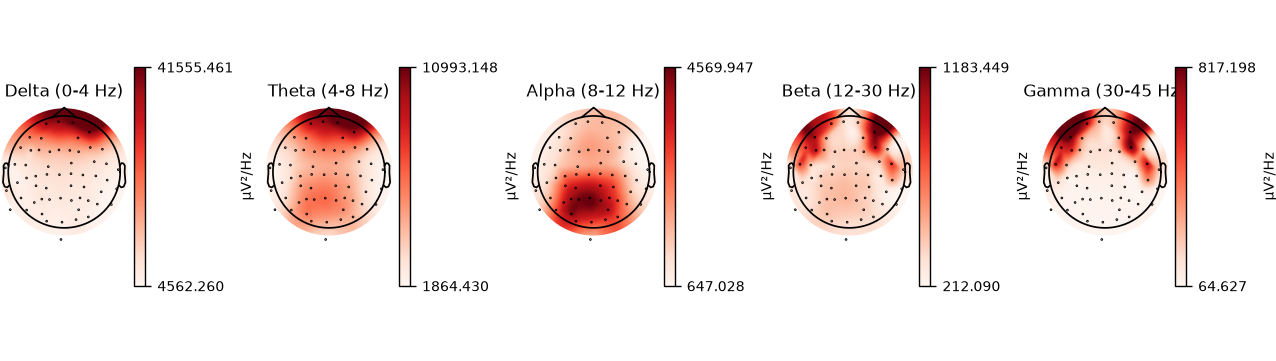
normalize: 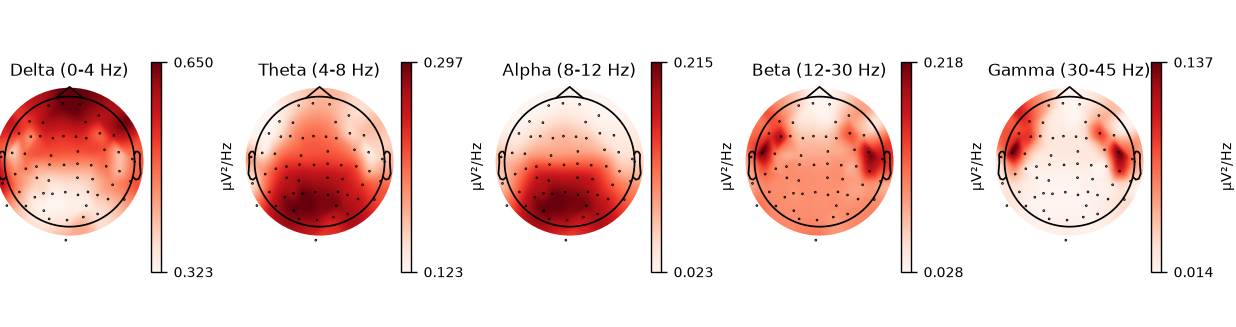

In [ ]:
# spectrum_auditory.plot_topomap(ch_type='mag', normalize=False,
#                                bands={'Custom1': (0, 10)})
# u can specify frequancy bands with your ranges as theta and beta and etc

In [ ]:
spectrum_auditory.plot_topomap(ch_type='grad', normalize=False)

<div class="alert alert-info">
    <b>REMARK</b>:
     <ul>
    <li>Sometimes it can be interesting  to consider the relative power, defined as the power in a given band divided by the total power. To explore this option, have a look at the "normalize" keyword. </li>
    </ul>
</div>

## Time-frequency analysis: power and inter-trial coherence

We now compute time-frequency representations (TFRs) from our Epochs.
We'll look at power and inter-trial coherence (ITC).

To this we'll use the method `epochs.compute_tfr(method='morlet')`
but you can also use `method='multitaper'` or `method='stockwell'`.

In [10]:
import numpy as np

# define frequencies of interest (log-spaced)
freqs = np.logspace(*np.log10([2, 30]), num=20)
freqs

array([ 2.        ,  2.30637295,  2.65967809,  3.0671048 ,  3.53694377,
        4.07875572,  4.70356592,  5.4240886 ,  6.25498562,  7.21316481,
        8.3181241 ,  9.5923482 , 11.0617662 , 12.75627917, 14.7103686 ,
       16.9637981 , 19.56242252, 22.55912106, 26.01487328, 30.        ])

In [ ]:
n_cycles = freqs / 2.  # different number of cycle per frequency
# tfr_morlet() is legacy -> use Epochs.compute_tfr()
power, itc = epochs_auditory.compute_tfr(
    method='morlet',
    freqs=freqs,
    n_cycles=n_cycles,
    use_fft=True,
    average=True,
    return_itc=True,
    decim=3,
    n_jobs=1,
)

In [20]:
power.crop(-0.1, 0.7)  # crop to remove edge artifacts

Data type,Average Power Estimates
Data source,Epochs
Number of epochs,364
Dims,"channel, freq, time"
Estimation method,morlet
Number of channels,364
Number of timepoints,161
Number of frequency bins,20
Frequency range,2.00 – 30.00 Hz


In [21]:
itc.crop(-0.1, 0.7)  # crop to remove edge artifacts

Data type,Inter-trial coherence
Data source,Epochs
Number of epochs,364
Dims,"channel, freq, time"
Estimation method,morlet
Number of channels,364
Number of timepoints,161
Number of frequency bins,20
Frequency range,2.00 – 30.00 Hz


Inspect power
-------------

<div class="alert alert-info"><h4>Note</h4><p>The generated figures are interactive. In the topo you can click
    on an image to visualize the data for one sensor.
    You can also select a portion in the time-frequency plane to
    obtain a topomap for a certain time-frequency region.</p></div>



In [24]:
baseline_mode = 'logratio'
baseline = (None, 0)

## Plot power topomap

In [ ]:
(power.copy()
 .pick('eeg')
 .plot_topo())

## Plot power of an individual channel

In [17]:
power.plot(picks='EEG 050', baseline=baseline, mode=baseline_mode)

[<Figure size 800x600 with 2 Axes>]

## Plot topomaps for specified frequency ranges

In [ ]:
import matplotlib.pyplot as plt

# 'title' is no longer a plot_topomap() argument -> set it on the axes.
# Data were cropped to -0.1..0.7 s, so tmax=1.5 was outside the data range.
fig, axis = plt.subplots(1, 3, figsize=(7, 4))
bands = {'Theta': (4, 7), 'Alpha': (8, 12), 'Beta': (15, 30)}
for ax, (name, (fmin, fmax)) in zip(axis, bands.items()):
    power.plot_topomap(ch_type='grad', tmin=0.5, tmax=0.7, fmin=fmin, fmax=fmax,
                       baseline=baseline, mode=baseline_mode, axes=ax,
                       show=False, contours=1)
    ax.set_title(name)
fig.tight_layout()
plt.show()

Joint Plot
----------
You can also create a joint plot showing both the aggregated TFR
across channels and topomaps at specific times and frequencies to obtain
a quick overview regarding oscillatory effects across time and space.



In [ ]:
power.plot_joint(baseline=baseline, mode='mean', tmin=None, tmax=None,
                 timefreqs=[(0.05, 2.), (0.1, 11.)])
plt.show()

Inspect ITC
-----------



In [ ]:
itc.plot_topo(title='Inter-Trial coherence', vmin=0., vmax=0.5, cmap='Reds')

<div class="alert alert-info"><h4>Note</h4><p>Baseline correction can be applied to power or done in plots.
    To illustrate the baseline correction in plots, the next line is
    commented power.apply_baseline(baseline=(-0.5, 0), mode='logratio')</p></div>

<div class="alert alert-success">
    <b>EXERCISE</b>:
     <ul>
      <li>Visualize the inter-trial coherence values as topomaps as done with
     power</li>
    </ul>
</div>